# Issue #366 — corrected-chronology fixed N7 expert

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
ROOT=Path.cwd().parents[2]
OUT=ROOT/'results/n7_chronology_sync'

In [2]:
performance=pd.read_csv(OUT/'performance.csv')
risk=pd.read_csv(OUT/'risk_diagnostics.csv')
bootstrap=pd.read_csv(OUT/'bootstrap_lift.csv')
coverage=pd.read_csv(OUT/'coverage_ledger.csv')
parity=pd.read_csv(OUT/'parity_summary.csv')
issue_parity=pd.read_parquet(OUT/'legacy_issue_parity.parquet')
performance

,scope,arm,issues,stake_cny,gross_cny,pnl_cny,ending_capital_cny,capital_return,stake_roi,hit_rate
0,2022,R0,51,52224.0,47532.938194,-4691.061806,95308.938194,-0.046911,-0.089826,0.215686
1,2022,R3,51,52224.0,24417.018861,-27806.981139,72193.018861,-0.278070,-0.532456,0.098039
2,2023,R0,46,47104.0,27390.339484,-19713.660516,80286.339484,-0.197137,-0.418514,0.195652
3,2023,R3,46,47104.0,86125.815382,39021.815382,139021.815382,0.390218,0.828418,0.152174
4,2024,R0,54,55296.0,63706.781092,8410.781092,108410.781092,0.084108,0.152105,0.351852
5,2024,R3,54,55296.0,76770.291987,21474.291987,121474.291987,0.214743,0.388352,0.259259
6,ALL,R0,151,154624.0,138630.058770,-15993.941230,84006.058770,-0.159939,-0.103438,0.258278
7,ALL,R3,151,154624.0,187313.126230,32689.126230,132689.126230,0.326891,0.211410,0.172185


In [3]:
risk

,scope,arm,max_drawdown_fraction,longest_losing_run,open_underwater_issues,largest_payout_share,payout_hhi
0,2022,R0,0.239363,11,51,0.277823,0.154369
1,2022,R3,0.331650,19,51,0.285977,0.215921
2,2023,R0,0.265765,14,44,0.216124,0.152064
3,2023,R3,0.124769,18,38,0.707551,0.523147
4,2024,R0,0.106794,6,29,0.185855,0.084930
5,2024,R3,0.174977,7,1,0.240748,0.134255
6,ALL,R0,0.302304,14,151,0.095259,0.042020
7,ALL,R3,0.331650,19,1,0.325329,0.136820


In [4]:
bootstrap

,scope,issues,matched_lift_cny,ex_largest_lift_cny,bootstrap_p025_cny,bootstrap_median_cny,bootstrap_p975_cny
0,2022,51,-23115.919333,-9910.179081,-61338.944178,-22555.534170,9140.018818
1,2023,46,58735.475898,-2202.906213,-26392.082409,54819.763196,198290.801997
2,2024,54,13063.510895,-5418.806106,-46801.113149,11163.424702,83314.801432
3,ALL,151,48683.067460,-12255.314651,-67786.263171,39643.093628,216261.934312


In [5]:
coverage_summary=(coverage.groupby(['issue_year','settlement_complete'],dropna=False).size().rename('issues').reset_index())
coverage_summary

,issue_year,settlement_complete,issues
0,2022,False,7
1,2022,True,51
2,2023,False,9
3,2023,True,46
4,2024,False,5
5,2024,True,54


In [6]:
parity

,layer,old_rows,new_rows,common_rows,exact_rows,year_exact_rows,fixture_exact_rows,support_exact_rows,settlement_exact_rows,score_exact_rows
0,issue_arm,210,302,208,136,192.0,152.0,145.0,186.0,NaN
1,ticket,26880,44032,26880,20764,NaN,NaN,NaN,NaN,NaN
2,action,32765,48658,32765,0,30061.0,NaN,32618.0,NaN,0.0


In [7]:
changed=issue_parity[(issue_parity['_merge']=='both') & (~issue_parity['exact_issue_arm'])]
changed[['issue','arm','old_issue_year','new_issue_year','exact_selected_match_ids','exact_support_json','exact_pnl_cny']].head(20)

,issue,arm,old_issue_year,new_issue_year,exact_selected_match_ids,exact_support_json,exact_pnl_cny
84,22112,R0,2023.0,2022.0,True,True,True
85,22112,R3,2023.0,2022.0,True,True,True
88,22114,R0,2023.0,2022.0,False,False,False
89,22114,R3,2023.0,2022.0,False,False,False
96,22123,R0,2023.0,2022.0,True,True,True
97,22123,R3,2023.0,2022.0,True,True,True
100,22126,R0,2023.0,2022.0,True,True,True
101,22126,R3,2023.0,2022.0,True,False,False
104,23012,R0,2023.0,2023.0,False,False,False
105,23012,R3,2023.0,2023.0,False,False,True


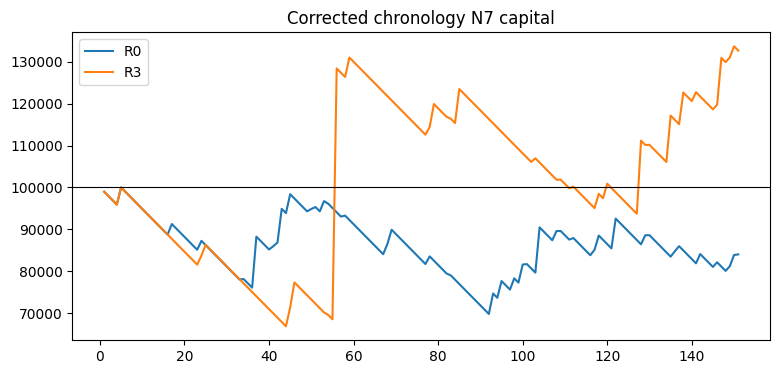

In [8]:
paths=pd.read_csv(OUT/'capital_paths.csv')
fig,ax=plt.subplots(figsize=(9,4))
for arm,g in paths[paths.scope.eq('ALL')].groupby('arm'):
    ax.plot(g.issue_order,g.capital_cny,label=arm)
ax.axhline(100000,color='black',lw=.8); ax.legend(); ax.set_title('Corrected chronology N7 capital'); plt.show()